# Collaborative filtering berbasis tetangga (user-based k-NN)

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/imamrozi/recsys-hibrida-multisinyal-notebooks/blob/main/notebooks/bab02_pendekatan_dasar/02_collaborative_filtering_knn.ipynb)

**Buku pendamping:** *Sistem Rekomendasi Hibrida Multi-Sinyal: Rating, Sentimen, dan Emosi* · Bab 2 · Kode 2.2.1

**Tujuan belajar**

- Menghitung kemiripan pengguna dari matriks rating yang jarang.
- Memprediksi rating dari k tetangga terdekat.
- Memahami trade-off nilai k: akurasi, cakupan, dan cold-start.

> **Catatan jujur.** Semua data di notebook ini **simulasi** dan dibuat agar mudah dijalankan (CPU, hitungan detik). Angka yang keluar menunjukkan *perilaku metode*, bukan hasil empiris pada dataset nyata, dan tidak boleh dikutip sebagai bukti. Kode bersifat ilustratif dan **belum production-ready** (tanpa validasi masukan, tanpa uji beban).

## 1. Kode dari buku

Lima pengguna dan enam item (Gambar 1.1).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

nan = np.nan
R = np.array([[5, 4, nan, 1, nan, nan],      # u1
              [4, nan, 5, nan, 1, nan],      # u2
              [nan, 5, 4, nan, nan, 2],      # u3
              [nan, nan, nan, 5, 4, nan],    # u4
              [nan, nan, nan, 4, 5, nan]])   # u5 (Gambar 1.1)


def kemiripan_pengguna(R, u):
    """Kosinus antara baris u dan baris lain, sel kosong dianggap 0."""
    Z = np.nan_to_num(R)
    sim = Z @ Z[u] / (np.linalg.norm(Z, axis=1) * np.linalg.norm(Z[u]))
    sim[u] = 0.0                                   # abaikan diri sendiri
    return sim


def prediksi_knn(R, u, i, k=2):
    """Rata-rata rating item i dari k tetangga terdekat, berbobot kemiripan."""
    sim = kemiripan_pengguna(R, u)
    penilai = np.where(~np.isnan(R[:, i]) & (sim > 0))[0]
    tetangga = penilai[np.argsort(-sim[penilai])][:k]
    if len(tetangga) == 0:
        return np.nan                              # tidak ada bukti: cold-start
    return float(sim[tetangga] @ R[tetangga, i] / sim[tetangga].sum())

In [2]:
print("kemiripan u2 ke u1..u5:", np.round(kemiripan_pengguna(R, 1), 3))
for i in (1, 3, 5):
    print(f"r_hat(u2, i{i + 1}) =", round(prediksi_knn(R, 1, i), 2))

kemiripan u2 ke u1..u5: [0.476 0.    0.46  0.096 0.12 ]
r_hat(u2, i2) = 4.49
r_hat(u2, i4) = 1.61
r_hat(u2, i6) = 2.0


Perhatikan i4 dan i6: u2 hanya punya satu atau dua tetangga yang menilainya, sehingga prediksi bertumpu pada bukti yang tipis.

## 2. Eksperimen A: skala lebih besar dengan data simulasi

Kita bangkitkan 300 pengguna × 120 item dengan struktur selera laten (4 kelompok), kepadatan 25%, lalu sembunyikan 20% rating untuk uji. Prediksi k-NN dibandingkan dengan baseline rata-rata global dan rata-rata item.

In [3]:
def simulasi_rating(m=300, n=120, g=4, density=0.25, noise=0.6, seed=1):
    rng = np.random.default_rng(seed)
    grup_u = rng.integers(0, g, m)                 # kelompok selera pengguna
    grup_i = rng.integers(0, g, n)                 # kelompok item
    cocok = np.where(grup_u[:, None] == grup_i[None, :], 4.2, 2.4)
    bias_u = rng.normal(0, 0.3, m)[:, None]
    bias_i = rng.normal(0, 0.3, n)[None, :]
    nilai = cocok + bias_u + bias_i + rng.normal(0, noise, (m, n))
    nilai = np.clip(np.round(nilai), 1, 5)
    mask = rng.random((m, n)) < density
    return np.where(mask, nilai, np.nan)

R_big = simulasi_rating()
obs = np.argwhere(~np.isnan(R_big))
rng = np.random.default_rng(0)
uji = obs[rng.choice(len(obs), size=int(0.2 * len(obs)), replace=False)]
R_latih = R_big.copy()
R_latih[uji[:, 0], uji[:, 1]] = np.nan
y_uji = R_big[uji[:, 0], uji[:, 1]]
print("pengguna x item:", R_big.shape, "| rating teramati:", len(obs),
      "| uji:", len(uji), "| kepadatan latih: %.1f%%" % (100 * (~np.isnan(R_latih)).mean()))

pengguna x item: (300, 120) | rating teramati: 8961 | uji: 1792 | kepadatan latih: 19.9%


In [4]:
def rmse(y, yh):
    ok = ~np.isnan(yh)
    return float(np.sqrt(np.mean((y[ok] - yh[ok]) ** 2))), float(ok.mean())

def knn_eval(R_latih, uji, y, ks, center=False):
    """RMSE uji k-NN. center=True: rata-rata tiap pengguna dikurangkan lebih dulu."""
    X = R_latih - np.nanmean(R_latih, axis=1, keepdims=True) if center else R_latih
    Z = np.nan_to_num(X)
    nrm = np.linalg.norm(Z, axis=1) + 1e-12
    S = (Z @ Z.T) / np.outer(nrm, nrm)
    np.fill_diagonal(S, 0.0)
    rows = []
    for k in ks:
        yh = np.full(len(uji), np.nan)
        for j, (u, i) in enumerate(uji):
            penilai = np.where(~np.isnan(R_latih[:, i]) & (S[u] > 0))[0]
            tet = penilai[np.argsort(-S[u, penilai])][:k]
            if len(tet):
                yh[j] = S[u, tet] @ R_latih[tet, i] / S[u, tet].sum()
        r, cakupan = rmse(y, yh)
        rows.append({"k": k, "RMSE": r, "cakupan_%": 100 * cakupan})
    return pd.DataFrame(rows).set_index("k")

mu = np.nanmean(R_latih)
rata_item = np.nanmean(R_latih, axis=0)
base_global = rmse(y_uji, np.full(len(uji), mu))[0]
base_item = rmse(y_uji, np.array([rata_item[i] if not np.isnan(rata_item[i]) else mu for _, i in uji]))[0]
ks = (1, 2, 5, 10, 20, 50)
hasil_mentah = knn_eval(R_latih, uji, y_uji, ks)
print("RMSE rata-rata global:", round(base_global, 3), "| rata-rata item:", round(base_item, 3))
print(hasil_mentah.round(3))

RMSE rata-rata global: 1.039 | rata-rata item: 1.013
     RMSE  cakupan_%
k                   
1   1.277      100.0
2   1.113      100.0
5   1.022      100.0
10  0.995      100.0
20  0.991      100.0
50  1.004      100.0


Dengan kosinus pada rating mentah (seperti di buku), keunggulan atas baseline rata-rata kecil. Semua rating bernilai positif, jadi kosinus banyak ditentukan oleh *seberapa banyak* item yang dinilai pengguna, bukan oleh *selera*-nya.

## 3. Eksperimen B: memusatkan rating per pengguna

Kurangi rata-rata tiap pengguna sebelum menghitung kosinus (ini setara dengan kosinus terpusat). Rating di atas kebiasaan pengguna jadi positif, di bawahnya negatif, sehingga selera ikut terbaca.

     RMSE  cakupan_%
k                   
1   0.994      100.0
2   0.871      100.0
5   0.806      100.0
10  0.807      100.0
20  0.820      100.0
50  0.832      100.0


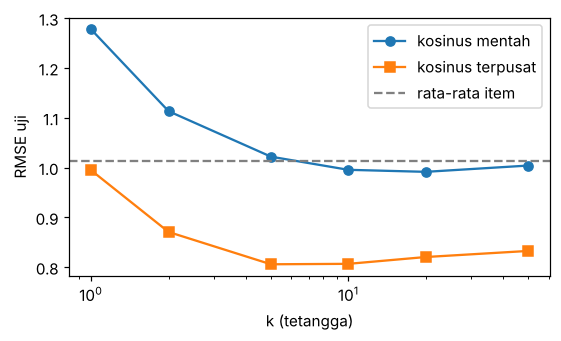

In [5]:
hasil_pusat = knn_eval(R_latih, uji, y_uji, ks, center=True)
print(hasil_pusat.round(3))

fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.plot(hasil_mentah.index, hasil_mentah["RMSE"], "o-", label="kosinus mentah")
ax.plot(hasil_pusat.index, hasil_pusat["RMSE"], "s-", label="kosinus terpusat")
ax.axhline(base_item, ls="--", c="gray", label="rata-rata item")
ax.set(xscale="log", xlabel="k (tetangga)", ylabel="RMSE uji")
ax.legend()
fig.tight_layout()

# klaim yang diuji: pemusatan memperbaiki hasil, dan k-NN terpusat mengalahkan baseline
assert hasil_pusat["RMSE"].min() < hasil_mentah["RMSE"].min() < base_global
assert hasil_pusat["RMSE"].min() < base_item

**Interpretasi (data simulasi).** *k* kecil berisik karena bertumpu pada satu atau dua tetangga. *k* sangat besar mencampur kelompok selera yang berbeda sehingga prediksi ditarik ke rata-rata. Titik terbaik ada di antaranya. Pemusatan rating memberi perbaikan yang jauh lebih besar daripada sekadar memilih *k* terbaik pada kosinus mentah. Pada matriks jarang, laporkan juga cakupan, bukan hanya RMSE.

## Pertanyaan refleksi

1. Mengapa sel kosong dianggap 0 pada `kemiripan_pengguna`, dan masalah apa yang ditimbulkan? (Petunjuk: bandingkan dengan kosinus yang dihitung pada item yang sama-sama dinilai.)
2. Apa yang terjadi pada cakupan jika kepadatan matriks diturunkan menjadi 3%?
3. Mengapa `simulasi_rating` membuat k-NN tampak bagus? Ciri data nyata apa yang tidak tertangkap?